In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import Rectangle, ConnectionPatch
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from mpl_toolkits.axes_grid1.inset_locator import mark_inset
from matplotlib.colors import LinearSegmentedColormap

In [2]:
#parameters plot
def plot_params(fontsize=18, tick_labelsize=12, legend_fontsize=18):
    """
    Update the parameters of the plot.

    Returns
    -------
    cmap : string
        The color map used in the colored plots.
    """
    plt.clf()
    plt.rc('font', size=fontsize)
    plt.rc('xtick', labelsize=tick_labelsize)
    plt.rc('ytick', labelsize=tick_labelsize)
    plt.rc('legend', fontsize=legend_fontsize)
    plt.rc('text', usetex=True)
    font = {'family' : 'stix'}
    plt.rc('font', **font)
    plt.rcParams["mathtext.fontset"] = "stix"
    mpl.rcParams['axes.linewidth'] = 1.3 #set the value globally
    plt.rc('xtick.major', size=8, width=1.3)
    plt.rc('ytick.major', size=8, width=1.3)

In [3]:
fig1 = pd.read_csv("/home/echipicoski/Documents/Projetos/Figuras_Yuri/Fig1/Lyapunov_avsb/plano_avsb.dat", 
                   sep=r"\s+", header=None, names=["b", "a", "l1", "l2", "l3"])
fig2 = pd.read_csv("/home/echipicoski/Documents/Projetos/Figuras_Yuri/Fig1/Lyapunov_cvsb/plano_cvsb.dat", 
                   sep=r"\s+", header=None, names=["b", "c", "l1", "l2", "l3"])

/tmp/ipykernel_89293/3448089870.py:164: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


<Figure size 640x480 with 0 Axes>

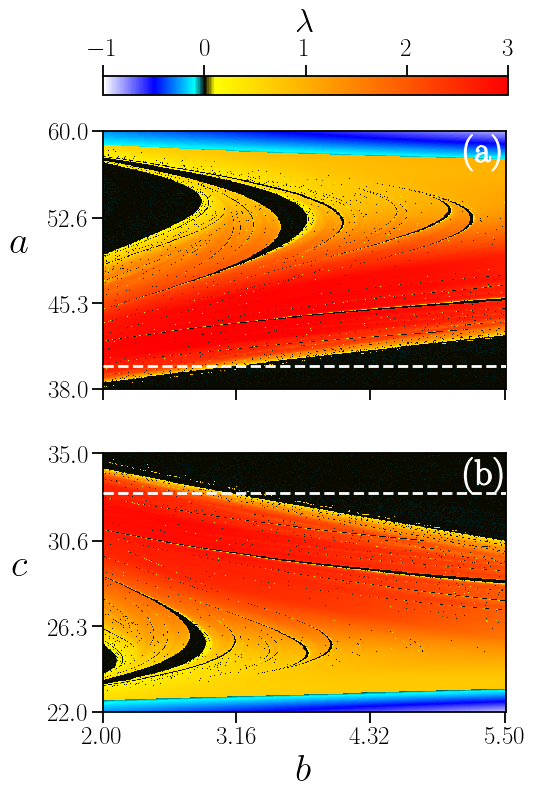

In [4]:
import matplotlib.patheffects as pe
plot_params(fontsize=28, tick_labelsize=18, legend_fontsize=18)
# ======================================================
# Paleta semelhante à do Gnuplot
# ======================================================

vals = np.array([
    -1.0,    # branco
    -0.5,    # azul
    -0.1,    # ciano
     0.0,    # preto
     0.1,    # amarelo
     3.0     # vermelho
])

# Normaliza os valores para [0,1]
vals_norm = (vals - vals.min()) / (vals.max() - vals.min())

colors = list(zip(
    vals_norm,
    ['white', 'blue', 'cyan', 'black', 'yellow', 'red']
))

cmap = LinearSegmentedColormap.from_list(
    "lyap",
    colors
)

# ======================================================
# Dados
# ======================================================

#fig1["lambda_plot"] = fig1["l1"]
#fig2["lambda_plot"] = fig2["l1"]
eps = 1e-5
fig1["lambda_plot"] = fig1["l1"] #np.where(np.abs(fig1["l1"]) < eps,fig1["l2"],fig1["l1"])
fig2["lambda_plot"] = fig2["l1"] #np.where(np.abs(fig2["l1"]) < eps,fig2["l2"],fig2["l1"])

# ======================================================
# Figura
# ======================================================

fig, ax = plt.subplots(
    2, 1,
    figsize=(6, 7.5),
    sharex=True
)


# ======================================================
# Painel (a)
# ======================================================

pcm = ax[0].scatter(
    fig1["b"],
    fig1["a"],
    c=fig1["lambda_plot"],
    cmap=cmap,
    vmin=-1,
    vmax=3,
    s=1,
    marker="s",
    linewidths=0
)

ax[0].set_xlim(2, 5.501)
ax[0].set_ylim(38, 60)
ax[0].set_xticks(np.arange(2, 5.501, 1))
ax[0].set_yticks([38, 45.3, 52.6, 60])
ax[0].set_ylabel(
    r"$a$",
    rotation=0,
    labelpad=20,
    fontsize=28
)

ax[0].text(
    0.89, 0.88,
    "(a)",
    transform=ax[0].transAxes,
    fontsize=26,
    color='white',
    fontweight="bold",
    path_effects=[
        pe.withStroke(linewidth=1.0, foreground="white")
    ]
)
ax[0].axhline(y=40.0,color="white",linestyle="--",linewidth=2,zorder=10)

# ======================================================
# Painel (b)
# ======================================================

ax[1].scatter(
    fig2["b"],
    fig2["c"],
    c=fig2["lambda_plot"],
    cmap=cmap,
    vmin=-1,
    vmax=3,
    s=1,
    marker="s",
    linewidths=0
)

ax[1].set_xlim(2, 5.501)
ax[1].set_ylim(22, 35)
ax[1].set_yticks([22, 26.3, 30.6, 35])
ax[1].set_xticks([2, 3.16, 4.32, 5.5])

ax[1].set_xlabel(r"$b$", fontsize=28)

ax[1].set_ylabel(
    r"$c$",
    rotation=0,
    labelpad=20,
    fontsize=28
)

ax[1].text(
    0.89, 0.88,
    "(b)",
    transform=ax[1].transAxes,
    fontsize=26,
    color='white',
    fontweight="bold",
    path_effects=[
        pe.withStroke(linewidth=1.0, foreground="white")
    ]
)
ax[1].axhline(y=33.0,color="white",linestyle="--",linewidth=2,zorder=10)



# ======================================================
# Colorbar
# ======================================================
# [left, bottom, width, height]
cax = fig.add_axes([0.225, 0.98, 0.675, 0.025])

cbar = fig.colorbar(
    pcm,
    cax=cax,
    orientation="horizontal"
)

cbar.ax.xaxis.set_ticks_position("top")
cbar.ax.xaxis.set_label_position("top")

cbar.set_label(
    r"$\lambda$",
    fontsize=24
)


# ======================================================
# Ajustes
# ======================================================

for a in ax:
    a.tick_params(axis="x", pad=2)
    a.tick_params(axis="y", pad=2)

plt.tight_layout()

plt.savefig(
    "fig1.jpeg",
    dpi=300,
    bbox_inches="tight"
)

plt.show()